# Assignment 2.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing

In [3]:
(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

(16512, 8) (16512,)
(4128, 8) (4128,)


The dataset consist **20 640 samples** with **8 numerical input features** and **the numerical target variable**.

In [4]:
# Calculate the split index (e.g., 80% for training, 20% for validation)
split_index = int(0.8 * len(inputs))

# Extract sets for training and validation
x_train = inputs[:split_index]
y_train = targets[:split_index]

x_val = inputs[split_index:]
y_val = targets[split_index:]

print(f"Training set shape: {x_train.shape}")
print(f"Validation set shape: {x_val.shape}")

Training set shape: (13209, 8)
Validation set shape: (3303, 8)


In [5]:

mean = x_train.mean(axis=0) # mean and standard deviation computed from training set only
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

Preprocess is now done.

In [6]:
model1 = Sequential([
    Input(shape=(8,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

model1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history1 = model1.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

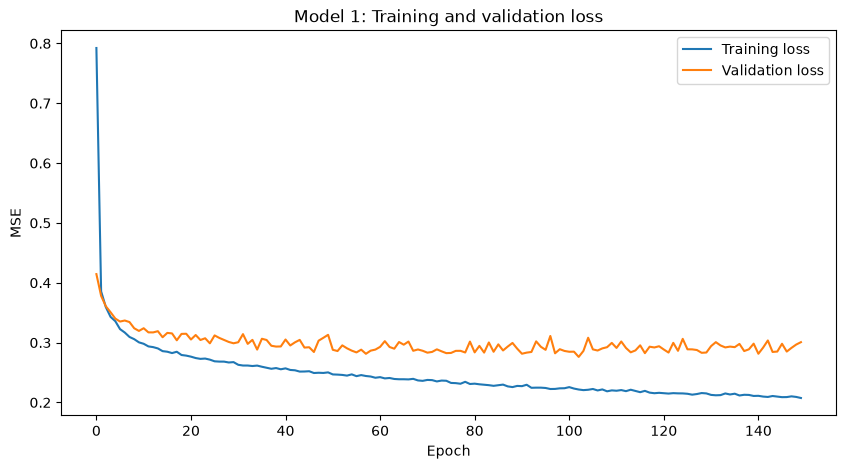

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(history1.history['loss'], label='Training loss')
plt.plot(history1.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Model 1: Training and validation loss')
plt.legend()
plt.show()

The initial model showed relatively stable training and validation losses. The difference between training and validation performance was not particularly large, suggesting that the model did not substantially overfit the training data.

Therefore, I decided to investigate a larger architecture with more parameters.

In [8]:
# define the model architecture
model2 = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

# configure the learning algorithm
model2.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [9]:
history2 = model2.fit(
    x_train, y_train, 
    epochs=150, 
    batch_size=32, 
    validation_data=(x_val, y_val), 
    verbose=1
)


Epoch 1/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.5246 - mae: 0.5063 - val_loss: 0.3842 - val_mae: 0.4418
Epoch 2/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3598 - mae: 0.4246 - val_loss: 0.3611 - val_mae: 0.4046
Epoch 3/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3320 - mae: 0.4036 - val_loss: 0.3400 - val_mae: 0.3935
Epoch 4/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3148 - mae: 0.3905 - val_loss: 0.3167 - val_mae: 0.3938
Epoch 5/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3116 - mae: 0.3885 - val_loss: 0.3182 - val_mae: 0.3729
Epoch 6/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3047 - mae: 0.3815 - val_loss: 0.3055 - val_mae: 0.3859
Epoch 7/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2960 - mae: 0.3777 - val_loss: 0.3659 - val_mae: 0.4322
Epoch 8/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2919 - mae: 0.3740 - val_loss: 0.3488 - val_mae: 0.3894
Epoch 9/150
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

Text(0, 0.5, 'Loss')

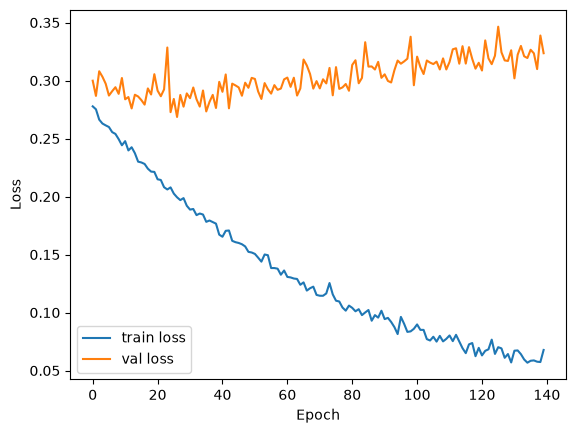

In [10]:

plt.plot(history2.history['loss'][10:], label='train loss')
plt.plot(history2.history['val_loss'][10:], label='val loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')

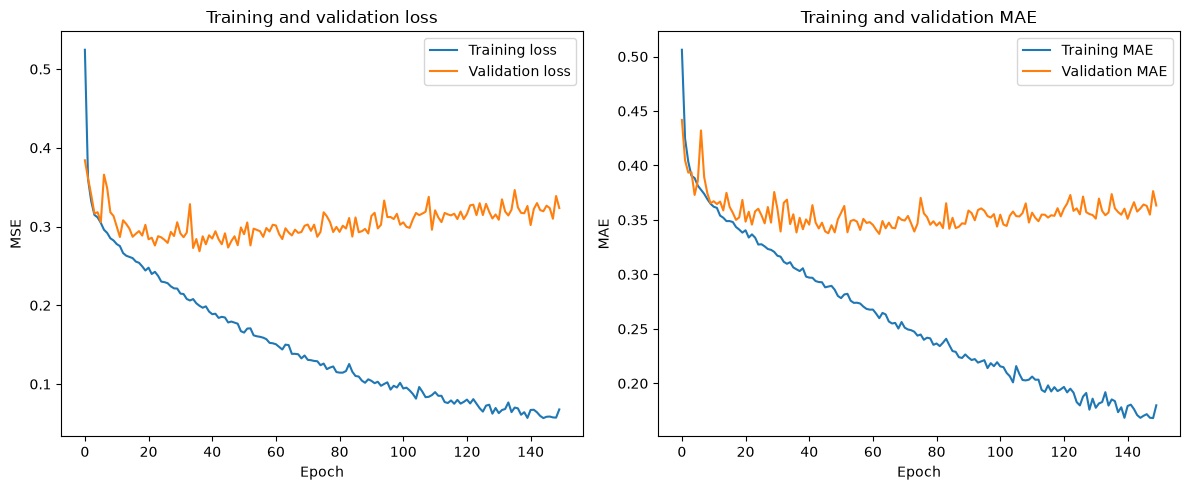

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history2.history['loss'], label='Training loss')
plt.plot(history2.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and validation loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history2.history['mae'], label='Training MAE')
plt.plot(history2.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training and validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
best_val_mae = min(history2.history['val_mae'])
print("Best validation MAE:", best_val_mae)

Best validation MAE: 0.3371962606906891


## 5. Experiment - Regularization

### 5.1 L2 regularization

In [13]:
from keras.regularizers import l2

model_l2 = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1)
])


In [14]:
model_l2.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [15]:
history_l2 = model_l2.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

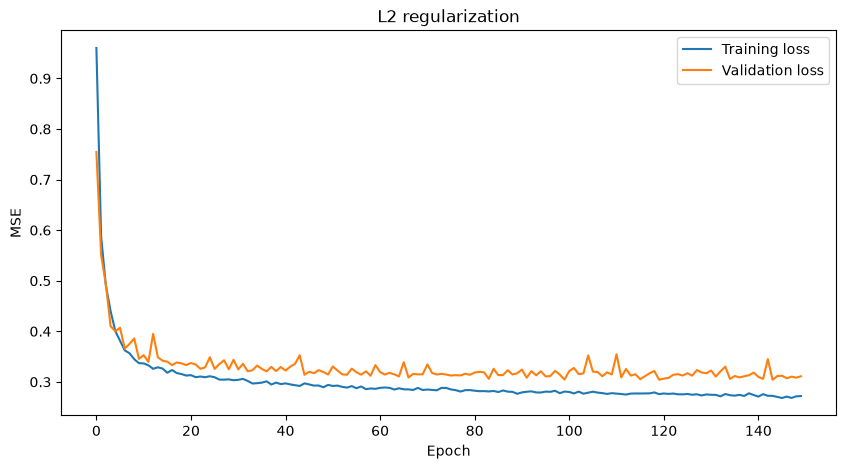

Best validation MAE (L2): 0.3405829668045044


In [16]:
plt.figure(figsize=(10, 5))

plt.plot(history_l2.history['loss'], label='Training loss')
plt.plot(history_l2.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('L2 regularization')
plt.legend()
plt.show()

best_l2 = min(history_l2.history['val_mae'])
print("Best validation MAE (L2):", best_l2)

### 5.2 Dropout

In [17]:
from keras.layers import Dropout

model_dropout = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dense(1)
])

model_dropout.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history_dropout = model_dropout.fit(
    x_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=0
)

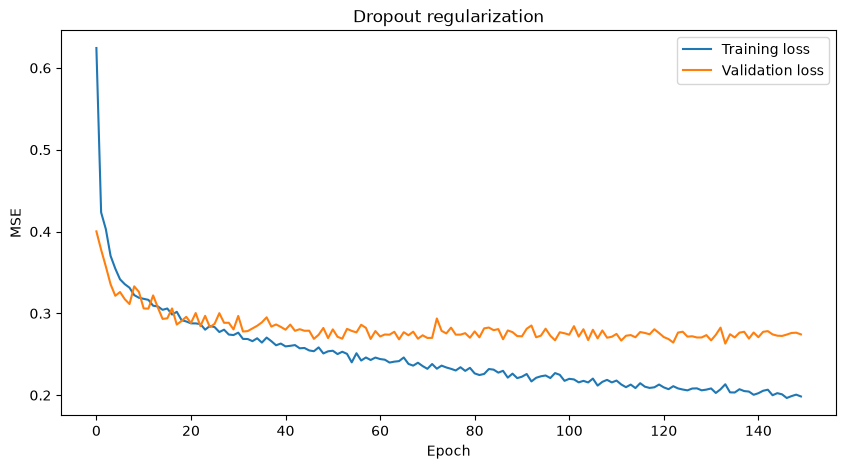

Best validation MAE (Dropout): 0.32774636149406433


In [18]:
plt.figure(figsize=(10, 5))

plt.plot(history_dropout.history['loss'], label='Training loss')
plt.plot(history_dropout.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Dropout regularization')
plt.legend()
plt.show()

best_dropout = min(history_dropout.history['val_mae'])
print("Best validation MAE (Dropout):", best_dropout)

### 5.3 Early stopping



In [ ]:
from keras.callbacks import EarlyStopping

model_early = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

model_early.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stopping = EarlyStopping(
    monitor='val_mae',
    patience=15,
    restore_best_weights=True
)

history_early = model_early.fit(
    x_train, y_train,
    epochs=500,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping],
    verbose=0
)

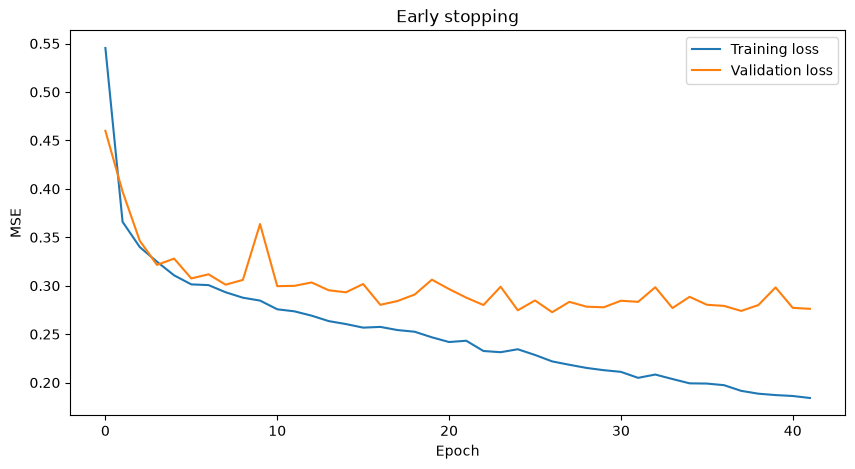

Validation MAE (Early stopping): 0.3398236334323883
Epochs trained: 42


In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history_early.history['loss'], label='Training loss')
plt.plot(history_early.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Early stopping')
plt.legend()
plt.show()

early_loss, early_mae = model_early.evaluate(
    x_val, y_val, verbose=0
)

print("Validation MAE (Early stopping):", early_mae)
print("Epochs trained:", len(history_early.history['loss']))

In [24]:
best_early = min(history_early.history['val_mae'])

results = {
    'L2': best_l2,
    'Dropout': best_dropout,
    'Early stopping': best_early
}

for name, mae in results.items():
    print(f'{name}: {mae:.4f}')

best_method = min(results, key=results.get)

print("\nBest regularization method:", best_method)
print("Best validation MAE:", results[best_method])

L2: 0.3406
Dropout: 0.3277
Early stopping: 0.3370

Best regularization method: Dropout
Best validation MAE: 0.32774636149406433


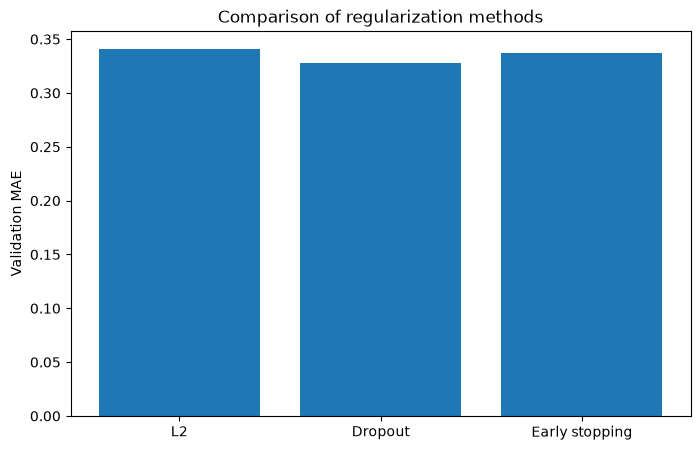

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.ylabel('Validation MAE')
plt.title('Comparison of regularization methods')
plt.show()

### Comparison and model selection

I compared the different regularization strategies using their validation MAE.

The method with the lowest validation MAE was selected as the most promising approach. This model will be used for the final training and evaluation.

The test dataset has not been used during model selection.

## 6. Final training and testing

After comparing the regularization techniques, I select the model with the lowest validation MAE.

I combine the training and validation datasets and train a new model from scratch using the selected architecture and regularization technique.

The number of training epochs is determined from the validation experiments.

Finally, I evaluate the model on the test dataset, which has not been used during training or model selection.

In [26]:
x_train_full = np.concatenate([x_train, x_val])
y_train_full = np.concatenate([y_train, y_val])

In [27]:
from keras.regularizers import l2

def build_final_model(method):

    model = Sequential()
    model.add(Input(shape=(8,)))

    if method == 'L2':
        for _ in range(4):
            model.add(Dense(
                256,
                activation='relu',
                kernel_regularizer=l2(0.001)
            ))

    elif method == 'Dropout':
        for _ in range(4):
            model.add(Dense(256, activation='relu'))
            if _ < 3:
                model.add(Dropout(0.2))

    elif method == 'Early stopping':
        for _ in range(4):
            model.add(Dense(256, activation='relu'))

    model.add(Dense(1))

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [28]:
histories = {
    'L2': history_l2,
    'Dropout': history_dropout,
    'Early stopping': history_early
}

best_epoch = np.argmin(
    histories[best_method].history['val_mae']
) + 1

print("Selected method:", best_method)
print("Selected epochs:", best_epoch)

Selected method: Dropout
Selected epochs: 136


In [29]:
final_model = build_final_model(best_method)

final_history = final_model.fit(
    x_train_full,
    y_train_full,
    epochs=best_epoch,
    batch_size=32,
    verbose=1
)

Epoch 1/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.5795 - mae: 0.5320
Epoch 2/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4157 - mae: 0.4564
Epoch 3/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3791 - mae: 0.4329
Epoch 4/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3625 - mae: 0.4230
Epoch 5/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3472 - mae: 0.4120
Epoch 6/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.3406 - mae: 0.4059
Epoch 7/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3259 - mae: 0.3990
Epoch 8/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3299 - mae: 0.4021
Epoch 9/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3202 - mae: 0.3942
Epoch 10/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3129 - mae: 0.3893
Epoch 11/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3123 - mae: 0.3887
Epoch 12/136
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.3122 - mae: 0.3889
Epoch 13/136


In [30]:
test_loss, test_mae = final_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Final test loss:", test_loss)
print("Final test MAE:", test_mae)

Final test loss: 0.27554476261138916
Final test MAE: 0.3406588137149811
